# 03. Evaluasi Kualitas Klaster K-Modes & Analisis Karakteristik Kategori
---

### **Tujuan Notebook:**
1. Memuat dataset terklasterisasi (`02_umkm_kmodes_clustered.csv`).
2. Menghitung kurva *Elbow* berbasis nilai *Cost* (Total Dissimilarity) untuk rentang $k = 2$ hingga $k = 7$ pada setiap partisi wilayah administrasi.
3. Melakukan tabulasi silang (*cross-tabulation*) antara `cluster_label`, `jenis_usaha`, dan instansi pembina (`skpd`).
4. Menyimpan ringkasan evaluasi ke `data/processed/03_kmodes_evaluation_summary.csv`.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from kmodes.kmodes import KModes

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print("Pustaka evaluasi K-Modes sukses dimuat.")

Pustaka evaluasi K-Modes sukses dimuat.


## 1. Memuat Dataset Hasil Klasterisasi K-Modes

In [2]:
file_path = os.path.join('..', 'data', 'processed', '02_umkm_kmodes_clustered.csv')
if not os.path.exists(file_path):
    file_path = '02_umkm_kmodes_clustered.csv'

df = pd.read_csv(file_path)
print(f"Dataset berhasil dimuat: {len(df):,} baris.")
df.head(5)

Dataset berhasil dimuat: 298,875 baris.


,periode_data,wilayah,skpd,jenis_usaha,nama_usaha,tahun,nama_pengusaha,cluster_label
0,2024,KAB. ADM. KEP. SERIBU,DINAS PARIWISATA DAN EKONOMI KREATIF,AGEN WISATA PERJALANAN (AWP),RADWA WISATA,2020,EVA OKTAVIANI,0
1,2024,KAB. ADM. KEP. SERIBU,DINAS PARIWISATA DAN EKONOMI KREATIF,FASHION,RAMA BUSANA,2021,RAMDA,0
2,2024,KAB. ADM. KEP. SERIBU,DINAS PARIWISATA DAN EKONOMI KREATIF,JASA CATERING,RANNI CATERING,2022,MOCH RASYID,0
3,2024,KAB. ADM. KEP. SERIBU,DINAS PARIWISATA DAN EKONOMI KREATIF,AGEN WISATA PERJALANAN (AWP),SADEWA TOURS,2020,SUGIWAN,0
4,2024,KAB. ADM. KEP. SERIBU,DINAS PARIWISATA DAN EKONOMI KREATIF,MAKANAN DAN MINUMAN,SAHABAT KITA CATERING,2022,FA'MI SUHAEMI,0


## 2. Pengujian Kurva Elbow K-Modes (*Cost vs k*)
Pada algoritma *K-Modes*, fungsi biaya (*Cost*) dihitung dari total jarak ketidakcocokan (*matching dissimilarity*)
$$\text{Cost} = \sum_{i=1}^{n} d(X_i, Q_{l_i})$$

In [3]:
def evaluate_kmodes_elbow(df_region, k_range=range(2, 8), random_state=42):
    """
    Menghitung nilai Cost K-Modes untuk variasi nilai k.
    """
    X_mat = df_region[['jenis_usaha', 'skpd']].astype(str).values
    costs = []
    k_vals = list(k_range)
    
    for k in k_vals:
        km = KModes(n_clusters=k, init='Cao', n_init=2, verbose=0, random_state=random_state, n_jobs=-1)
        km.fit(X_mat)
        costs.append(km.cost_)
        print(f"  k={k} -> Cost: {km.cost_:,}")
        
    return k_vals, costs

## 3. Eksekusi dan Visualisasi Kurva Elbow untuk Seluruh Wilayah
Menghitung dan memplot kurva *Cost vs k* untuk 6 wilayah administrasi.


--- Evaluasi Elbow: KAB. ADM. KEP. SERIBU ---
  k=2 -> Cost: 3,252.0
  k=3 -> Cost: 2,887.0
  k=4 -> Cost: 2,849.0
  k=5 -> Cost: 2,558.0
  k=6 -> Cost: 2,401.0

--- Evaluasi Elbow: KOTA ADM. JAKARTA BARAT ---
  k=2 -> Cost: 45,029.0
  k=3 -> Cost: 41,090.0
  k=4 -> Cost: 38,478.0
  k=5 -> Cost: 36,381.0
  k=6 -> Cost: 34,839.0

--- Evaluasi Elbow: KOTA ADM. JAKARTA PUSAT ---
  k=2 -> Cost: 38,984.0
  k=3 -> Cost: 35,398.0
  k=4 -> Cost: 31,561.0
  k=5 -> Cost: 28,378.0
  k=6 -> Cost: 26,723.0

--- Evaluasi Elbow: KOTA ADM. JAKARTA SELATAN ---
  k=2 -> Cost: 65,437.0
  k=3 -> Cost: 60,756.0
  k=4 -> Cost: 56,548.0
  k=5 -> Cost: 54,094.0
  k=6 -> Cost: 51,804.0

--- Evaluasi Elbow: KOTA ADM. JAKARTA TIMUR ---
  k=2 -> Cost: 53,531.0
  k=3 -> Cost: 49,252.0
  k=4 -> Cost: 45,411.0
  k=5 -> Cost: 43,291.0
  k=6 -> Cost: 41,766.0

--- Evaluasi Elbow: KOTA ADM. JAKARTA UTARA ---
  k=2 -> Cost: 39,140.0
  k=3 -> Cost: 34,558.0
  k=4 -> Cost: 31,373.0
  k=5 -> Cost: 30,327.0
  k=6 -> Cost: 

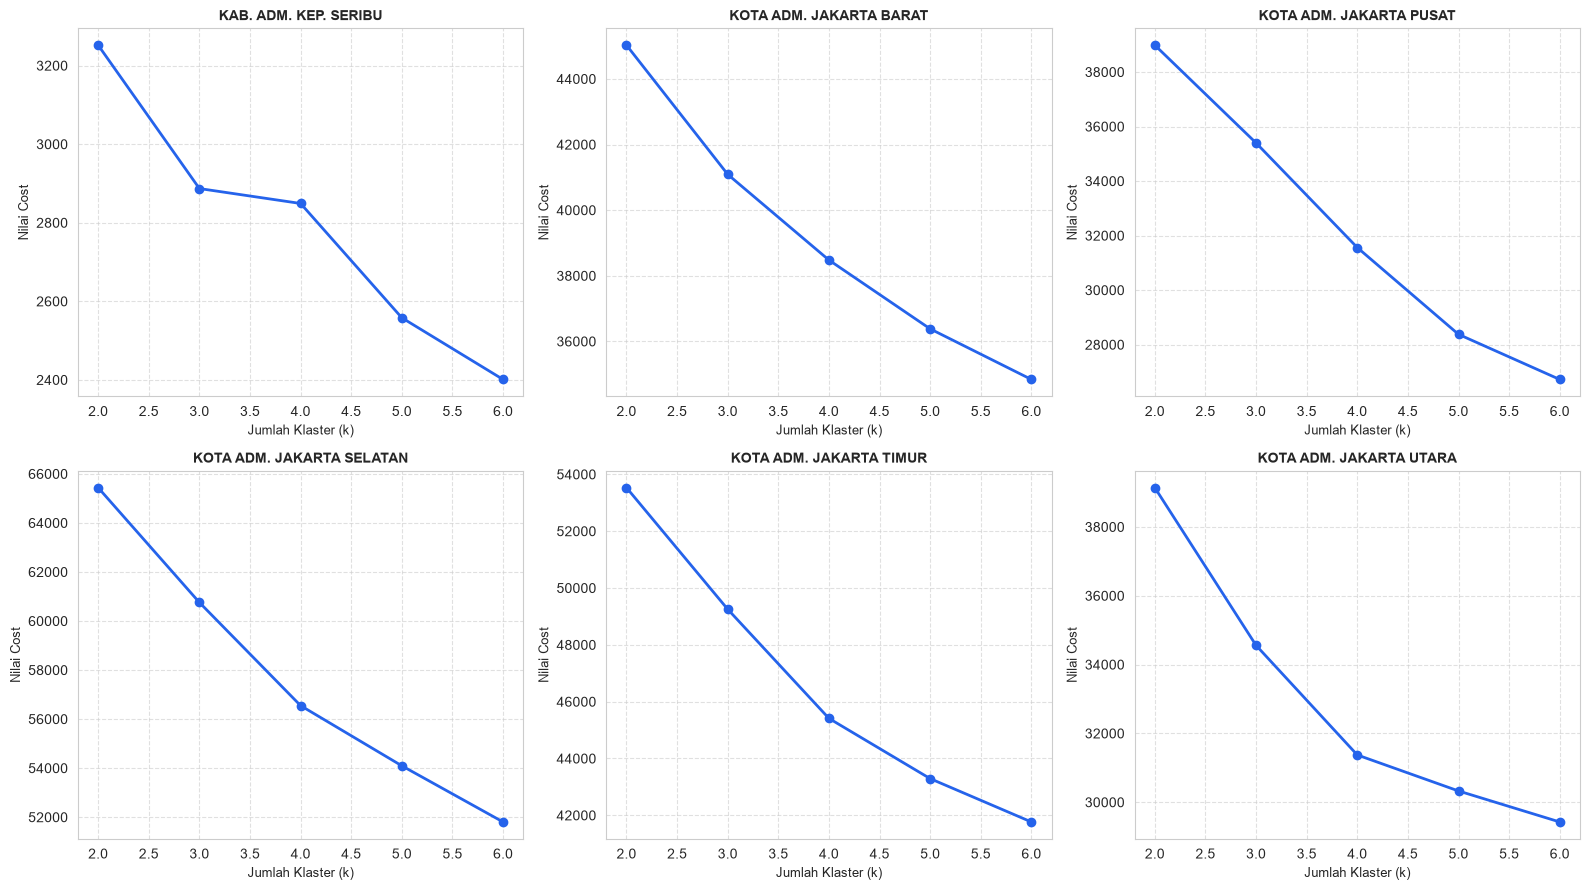

In [4]:
daftar_wilayah = sorted(df['wilayah'].unique().tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

elbow_records = []

for idx, wil in enumerate(daftar_wilayah):
    print(f"\n--- Evaluasi Elbow: {wil} ---")
    df_wil = df[df['wilayah'] == wil]
    k_vals, costs = evaluate_kmodes_elbow(df_wil, k_range=range(2, 7))
    
    for k, c in zip(k_vals, costs):
        elbow_records.append({'wilayah': wil, 'k': k, 'cost': c})
        
    # Plotting grafik kurva
    axes[idx].plot(k_vals, costs, marker='o', color='#2563EB', linewidth=2, markersize=6)
    axes[idx].set_title(f"{wil}", fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("Jumlah Klaster (k)", fontsize=9)
    axes[idx].set_ylabel("Nilai Cost", fontsize=9)
    axes[idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

df_elbow = pd.DataFrame(elbow_records)

## 4. Analisis Asosiasi Klaster & Dominasi Instansi Pembina (SKPD)
Menganalisis keterkaitan antara klaster yang terbentuk dengan instansi pembina utama pada masing-masing wilayah

In [5]:
sample_wil = 'KOTA ADM. JAKARTA SELATAN'
df_sample = df[df['wilayah'] == sample_wil]

print(f"=== TABULASI SILANG KLASTER VS SKPD PEMBINA ({sample_wil}) ===")
crosstab_skpd = pd.crosstab(
    df_sample['cluster_label'], 
    df_sample['skpd'], 
    margins=True, 
    margins_name="Total"
)
display(crosstab_skpd)

=== TABULASI SILANG KLASTER VS SKPD PEMBINA (KOTA ADM. JAKARTA SELATAN) ===


skpd,DINAS PARIWISATA DAN EKONOMI KREATIF,DINAS SOSIAL,SUKU DINAS KETAHANAN PANGAN KELAUTAN DAN PERTANIAN KOTA ADM. JAKARTA SELATAN,SUKU DINAS KETAHANAN PANGAN KELAUTAN DAN PERTANIAN KOTA ADM. JAKARTA TIMUR,SUKU DINAS KETAHANAN PANGAN KELAUTAN DAN PERTANIAN KOTA ADM. JAKARTA UTARA,"SUKU DINAS KETAHANAN PANGAN, KELAUTAN, DAN PERTANIAN KOTA ADMINISTRASI JAKARTA BARAT","SUKU DINAS KETAHANAN PANGAN, KELAUTAN, DAN PERTANIAN KOTA ADMINISTRASI JAKARTA PUSAT","SUKU DINAS KETAHANAN PANGAN, KELAUTAN, DAN PERTANIAN KOTA ADMINISTRASI JAKARTA SELATAN","SUKU DINAS KETAHANAN PANGAN, KELAUTAN, DAN PERTANIAN KOTA ADMINISTRASI JAKARTA TIMUR","SUKU DINAS KETAHANAN PANGAN, KELAUTAN, DAN PERTANIAN KOTA ADMINISTRASI JAKARTA UTARA","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KABUPATEN ADMINISTRASI KEPULAUAN SERIBU","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KOTA ADMINISTRASI JAKARTA BARAT","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KOTA ADMINISTRASI JAKARTA PUSAT","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KOTA ADMINISTRASI JAKARTA SELATAN","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KOTA ADMINISTRASI JAKARTA TIMUR","SUKU DINAS PEMBERDAYAAN, PERLINDUNGAN ANAK, DAN PENGENDALIAN PENDUDUK KOTA ADMINISTRASI JAKARTA UTARA","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KABUPATEN ADMINISTRASI KEPULAUAN SERIBU","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADM. JAKARTA BARAT","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADM. JAKARTA PUSAT","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADM. JAKARTA SELATAN","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADM. JAKARTA TIMUR","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADM. JAKARTA UTARA","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADMINISTRASI JAKARTA BARAT","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADMINISTRASI JAKARTA PUSAT","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADMINISTRASI JAKARTA SELATAN","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADMINISTRASI JAKARTA TIMUR","SUKU DINAS PERINDUSTRIAN, PERDAGANGAN, KOPERASI, USAHA KECIL DAN MENENGAH KOTA ADMINISTRASI JAKARTA UTARA",SUKU DINAS PPA DAN PENGENDALIAN PENDUDUK KOTA ADM JAKARTA SELATAN,"SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADM. JAKARTA PUSAT","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADM. JAKARTA SELATAN","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADMINISTRASI JAKARTA BARAT","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADMINISTRASI JAKARTA PUSAT","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADMINISTRASI JAKARTA SELATAN","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADMINISTRASI JAKARTA TIMUR","SUKU DINAS TENAGA KERJA, TRANSMIGRASI, DAN ENERGI KOTA ADMINISTRASI JAKARTA UTARA",Total
cluster_label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1211,1347,44,1,1,113,27,4637,19,5,4,172,13,2000,13,19,4,9,5,6056,6,2,1483,115,42406,121,40,40,137,388,161,11,3924,6,19,64559
1,42,38,27,0,0,0,2,131,0,0,0,0,0,51,0,0,0,10,3,6669,5,1,15,23,6953,11,8,10,86,147,0,0,418,0,0,14650
2,99,34,0,0,0,1,0,3,0,1,0,20,0,164,2,4,0,2,0,416,0,0,190,5,3537,14,3,2,0,2,8,0,173,0,1,4681
Total,1352,1419,71,1,1,114,29,4771,19,6,4,192,13,2215,15,23,4,21,8,13141,11,3,1688,143,52896,146,51,52,223,537,169,11,4515,6,20,83890


## 5. Ringkasan Karakteristik 5 Komoditas Terbesar per Klaster

In [6]:
print(f"=== 5 KOMODITAS UTAMA DI SETIAP KLASTER ({sample_wil}) ===")
for c in sorted(df_sample['cluster_label'].unique()):
    sub_c = df_sample[df_sample['cluster_label'] == c]
    top_5 = sub_c['jenis_usaha'].value_counts().head(5)
    pct_total = (len(sub_c) / len(df_sample)) * 100
    
    print(f"\n[ Klaster {c} ] - Populasi: {len(sub_c):,} UMKM ({pct_total:.1f}%)")
    for ju, count in top_5.items():
        print(f"   * {ju:<35}: {count:>5,} unit ({(count/len(sub_c))*100:.1f}%)")

=== 5 KOMODITAS UTAMA DI SETIAP KLASTER (KOTA ADM. JAKARTA SELATAN) ===

[ Klaster 0 ] - Populasi: 64,559 UMKM (77.0%)
   * MAKANAN DAN MINUMAN                : 34,797 unit (53.9%)
   * WARUNG SEMBAKO                     : 4,208 unit (6.5%)
   * KUE BASAH                          : 2,454 unit (3.8%)
   * KEDAI MAKANAN                      : 2,290 unit (3.5%)
   * RUMAH/WARUNG MAKAN                 : 2,054 unit (3.2%)

[ Klaster 1 ] - Populasi: 14,650 UMKM (17.5%)
   * PRODUK MAKANAN LAINNYA             : 14,650 unit (100.0%)

[ Klaster 2 ] - Populasi: 4,681 UMKM (5.6%)
   * FASHION                            : 4,681 unit (100.0%)


## 6. Penyimpanan Rekapitulasi Hasil Evaluasi
Menyimpan tabel evaluasi *Elbow Cost* ke `data/processed/03_kmodes_evaluation_summary.csv`[cite: 1].

In [7]:
eval_out = os.path.join('..', 'data', 'processed', '03_kmodes_evaluation_summary.csv')
df_elbow.to_csv(eval_out, index=False)

print(f"Hasil evaluasi Cost K-Modes berhasil disimpan di: {eval_out}")

Hasil evaluasi Cost K-Modes berhasil disimpan di: ..\data\processed\03_kmodes_evaluation_summary.csv
